In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define o estilo visual
sns.set_theme(style="whitegrid")

# Força o fundo branco
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.edgecolor": "black"
})


In [18]:
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Dicionário de Dados — Telco Customer Churn

**Fonte:** [Kaggle — Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

**Descrição:** Conjunto de dados com 7.043 registros de clientes e 21 variáveis, contendo informações demográficas, serviços contratados, características financeiras e histórico de cancelamento.

### 1. Identificação e perfil do cliente

| Variável | Descrição |
|---|---|
| `customerID` | Identificador único do cliente |
| `gender` | Gênero do cliente |
| `SeniorCitizen` | Indica se o cliente é idoso (1 = Sim, 0 = Não) |
| `Partner` | Indica se o cliente possui companheiro(a) |
| `Dependents` | Indica se o cliente possui dependentes |

### 2. Serviços contratados

| Variável | Descrição |
|---|---|
| `PhoneService` | Indica se possui serviço de telefonia |
| `MultipleLines` | Indica se possui múltiplas linhas telefônicas |
| `InternetService` | Tipo de serviço de internet (DSL, fibra óptica ou nenhum) |
| `OnlineSecurity` | Indica se possui serviço de segurança online |
| `OnlineBackup` | Indica se possui serviço de backup online |
| `DeviceProtection` | Indica se possui proteção de dispositivos |
| `TechSupport` | Indica se possui suporte técnico |
| `StreamingTV` | Indica se possui serviço de streaming de TV |
| `StreamingMovies` | Indica se possui serviço de streaming de filmes |

### 3. Informações contratuais e financeiras

| Variável | Descrição |
|---|---|
| `tenure` | Tempo de permanência do cliente, em meses |
| `Contract` | Tipo de contrato: mensal, anual ou bienal |
| `PaperlessBilling` | Indica se utiliza faturamento sem papel |
| `PaymentMethod` | Método de pagamento utilizado |
| `MonthlyCharges` | Valor cobrado mensalmente do cliente |
| `TotalCharges` | Valor total cobrado ao cliente durante seu relacionamento com a empresa |

### 4. Cancelamento

| Variável | Descrição |
|---|---|
| `Churn` | Indica se o cliente cancelou o serviço no último mês (Yes = Sim, No = Não) |

### Observações sobre os dados

- Cada linha representa um cliente.
- `SeniorCitizen` é uma variável categórica binária, apesar de armazenada numericamente.
- `tenure` representa meses completos de permanência.
- `TotalCharges` requer conversão para formato numérico.
- As categorias "No internet service" e "No phone service" indicam ausência do serviço principal correspondente.
- O dataset não fornece uma data individual de referência para cada cliente.

**Referência:** IBM Sample Data Sets, disponibilizado no Kaggle por BlastChar.

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Tratamento de valores ausentes — TotalCharges

Durante a análise de qualidade dos dados, foram identificados 11 registros com valores ausentes na variável `TotalCharges`, representando aproximadamente 0,16% do dataset.

A investigação demonstrou que todos esses registros possuem `tenure = 0`, indicando clientes sem meses completos de permanência.

**Decisão adotada:** substituir os valores ausentes por zero, considerando a hipótese de que esses clientes ainda não possuem faturamento acumulado.

**Justificativa:** preservar as observações e evitar a exclusão de clientes potencialmente recém-cadastrados.

**Limitação:** a ausência de faturamento acumulado não foi confirmada por registros financeiros externos. Portanto, a substituição representa uma hipótese analítica que deve ser considerada na interpretação dos resultados.

In [20]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


In [21]:
# Verificar valores ausentes por variável
df.isna().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

## 02 — Análise Univariada

### 2.1 — Variáveis Quantitativas

Nesta etapa, serão analisadas as distribuições das variáveis
quantitativas, considerando medidas de tendência central,
dispersão e posição.

In [22]:
variaveis_quantitativas = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

df[variaveis_quantitativas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80


In [23]:
# Coeficiente de Variação (CV) das variáveis quantitativas
cv_tenure = df['tenure'].std() / df['tenure'].mean()
print(cv_tenure.round(2))
cv_monthly = df['MonthlyCharges'].std() / df['MonthlyCharges'].mean()
print(cv_monthly.round(2))
cv_total = df['TotalCharges'].std() / df['TotalCharges'].mean()
print(cv_total.round(2))

0.76
0.46
0.99


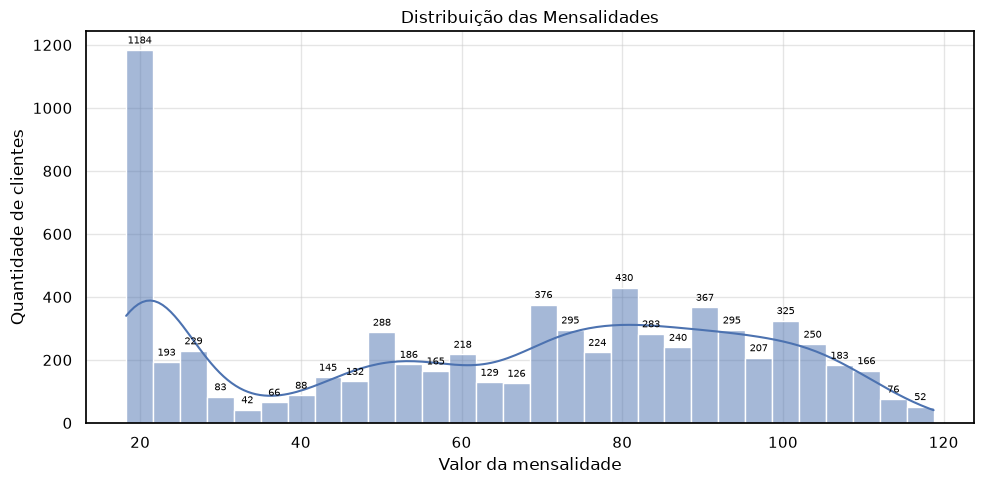

In [33]:
# plt.figure(figsize=(10, 5))

fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x='MonthlyCharges',
    bins=30,
    kde=True,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=7)

plt.title('Distribuição das Mensalidades')
plt.xlabel('Valor da mensalidade')
plt.ylabel('Quantidade de clientes')

plt.tight_layout()
plt.show()

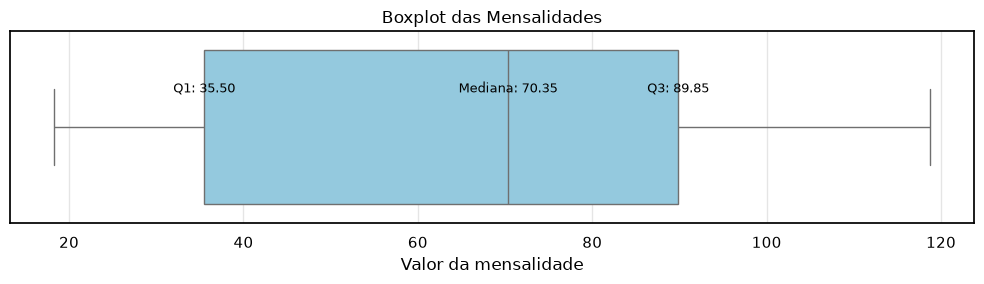

In [34]:
# plt.figure(figsize=(10, 3))

fig, ax = plt.subplots(figsize=(10, 3))

sns.boxplot(
    data=df,
    x='MonthlyCharges',
    color='skyblue',
    ax=ax
)

q1 = df['MonthlyCharges'].quantile(0.25)
mediana = df['MonthlyCharges'].median()
q3 = df['MonthlyCharges'].quantile(0.75)

for valor, nome in [
    (q1, 'Q1'),
    (mediana, 'Mediana'),
    (q3, 'Q3')
]:
    ax.annotate(
        f'{nome}: {valor:,.2f}',
        xy=(valor, 0),
        xytext=(0, 25),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

plt.title('Boxplot das Mensalidades')
plt.xlabel('Valor da mensalidade')

plt.tight_layout()
plt.show()

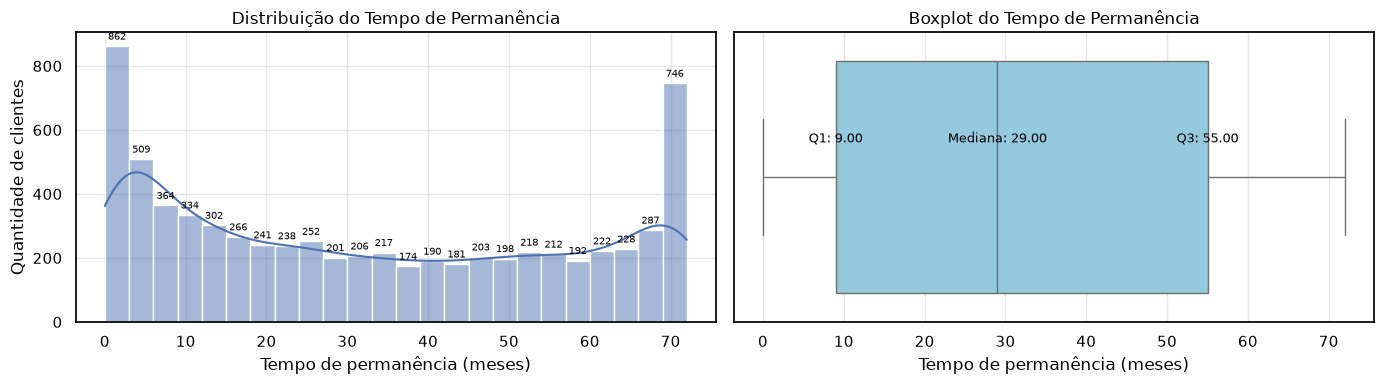

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histograma
sns.histplot(
    data=df,
    x='tenure',
    bins=24,
    kde=True,
    ax=axes[0]
)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f', padding=3, fontsize=7)

axes[0].set_title('Distribuição do Tempo de Permanência')
axes[0].set_xlabel('Tempo de permanência (meses)')
axes[0].set_ylabel('Quantidade de clientes')

# Boxplot
sns.boxplot(
    data=df,
    x='tenure',
    ax=axes[1],
    color='skyblue'
)

q1 = df['tenure'].quantile(0.25)
mediana = df['tenure'].median()
q3 = df['tenure'].quantile(0.75)

for valor, nome in [
    (q1, 'Q1'),
    (mediana, 'Mediana'),
    (q3, 'Q3')
]:
    axes[1].annotate(
        f'{nome}: {valor:,.2f}',
        xy=(valor, 0),
        xytext=(0, 25),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

axes[1].set_title('Boxplot do Tempo de Permanência')
axes[1].set_xlabel('Tempo de permanência (meses)')

plt.tight_layout()
plt.show()

### Investigação do porque existem tantos dados concentrados em cliente em torno de 70 meses

In [27]:
# Frequência de clientes por tempo de permanência
frequencia_tenure = (
    df['tenure']
    .value_counts()
    .sort_index()
)

# Últimos 15 valores de tenure
frequencia_tenure.tail(15)

tenure
58     67
59     60
60     76
61     76
62     70
63     72
64     80
65     76
66     89
67     98
68    100
69     95
70    119
71    170
72    362
Name: count, dtype: int64

In [28]:
pd.crosstab(
    df['tenure'] == 72,
    df['Contract'],
    normalize='index'
).round(3)

Contract,Month-to-month,One year,Two year
tenure,,,
False,0.580,0.218,0.202
True,0.006,0.047,0.948


In [29]:
df.groupby('Contract')['tenure'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)

,count,mean,median,min,max
Contract,,,,,
Month-to-month,3875,18.04,12.0,1,72
One year,1473,42.04,44.0,0,72
Two year,1695,56.74,64.0,0,72


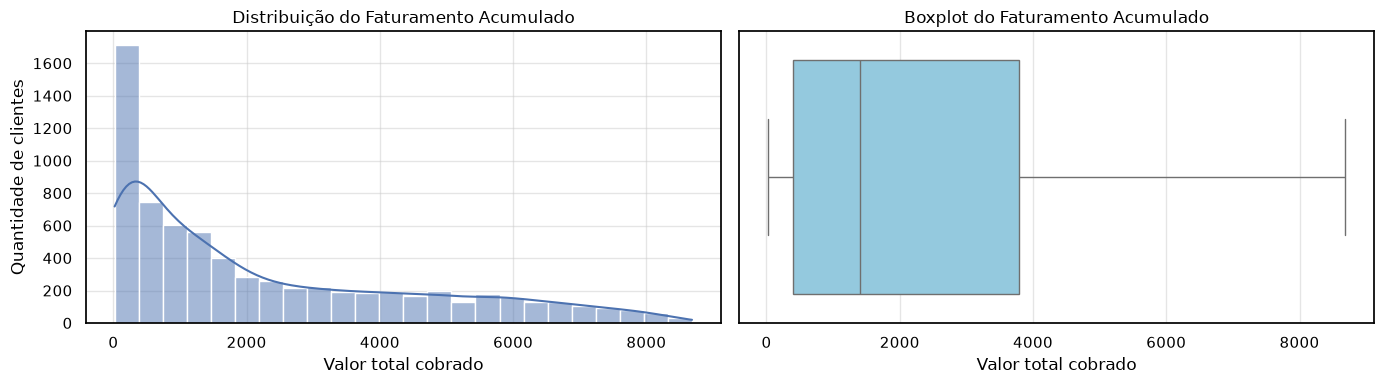

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histograma
sns.histplot(
    data=df,
    x='TotalCharges',
    bins=24,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Distribuição do Faturamento Acumulado')
axes[0].set_xlabel('Valor total cobrado')
axes[0].set_ylabel('Quantidade de clientes')

# Boxplot
sns.boxplot(
    data=df,
    x='TotalCharges',
    ax=axes[1],
    color='skyblue'
)

axes[1].set_title('Boxplot do Faturamento Acumulado')
axes[1].set_xlabel('Valor total cobrado')

plt.tight_layout()
plt.show()